# Energy-Aware Task Offloading in MEC (extension of the DRL replication)
## Based on Jiang et al., IEEE IoT Journal, Vol. 12, No. 8, April 2025

$$\min_{\Phi}\ \sum_{n=1}^{N} \left(T_n + w_E\,E_n\right),\qquad \Phi=\{f^L,\ P_n,\ \alpha_n,\ \beta_n,\ \gamma_n,\ x_{n,m}\}$$

s.t. $\alpha_n+\beta_n+\gamma_n=1$, $0\le\alpha_n,\beta_n,\gamma_n\le1$, $\sum_m x_{n,m}\le1$, $x_{n,m}\in\{0,1\}$,
$0\le f^L\le f^{L,\max}$, $0\le P_n\le P_{n,\max}$, with

- $R_{n,m}=B\log_2\!\left(1+\frac{P_n h}{I_{n,j}+\delta^2}\right)$
- $E_n^{comp}=K\,(f^L)^2\,\alpha_n d_n \varphi_n$, $\quad E_n^{off}=P_n\,\frac{(\beta_n+\gamma_n)d_n}{R_{n,m}}=P_n t_n^{comm}$, $\quad E_n=E_n^{comp}+E_n^{off}$
- $T_n=\max(t_n^L,t_n^E,t_n^C)$ as in the paper, with $f^L$ replacing the fixed local CPU capacity.

**Baseline DQN** = the original latency-only DQN (fixed $f^L$ = 1 GHz, $P$ = 23 dBm).
**Enhanced DQN** = additionally chooses $f^L$ and $P_n$ and minimises $T_n + w_E E_n$. Both share the same limits.

In [17]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {DEV}')

Using: cpu


In [18]:
# System Parameters (Table I)
M = 5; N = 50; NC = 10
BW = 1e6
P_W = 10**((23-30)/10)
N0_W = 10**((-70-30)/10)
C_L = 1e9; C_E = 20e9; C_C = 100e9; C_WIRE = 1e9
AREA = 600
SCALE = 2.7

SIZES = {'I':[256,512,768,1024], 'II':[512,1024,1536,2048],
         'III':[768,1536,2304,3072], 'IV':[1024,2048,3072,4096]}
CPU_RANGE = (100, 500)

def path_loss_db(d):
    return 35 + 25 * np.log10(np.maximum(d, 1.0))


# ---- Energy extension (Board_Equations_New.docx) ----
K_EFF = 1e-27                  # effective switched-capacitance coefficient
F_MAX = C_L                    # f_L,max = 1 GHz (paper's fixed local CPU)
P_MAX = P_W                    # P_n,max = 23 dBm (paper's fixed Tx power)
F_LEVELS = [x * F_MAX for x in (0.25, 0.5, 0.75, 1.0)]
P_LEVELS = [x * P_MAX for x in (0.25, 0.5, 0.75, 1.0)]
W_E = 1.0                      # weight on energy: objective = T[ms] + W_E * E[mJ]

def cost(T, E, w_e=None):
    return T + (W_E if w_e is None else w_e) * E

In [19]:
class MECSystem:
    """MEC with fixed inter-EN interference (Eq. 4). DQN uses clean rates, others use degraded.
    Energy extension: rates depend on transmit power P, latency on local CPU frequency f_L."""
    def __init__(self, scenario='II', seed=SEED):
        self.scenario = scenario
        rng = np.random.RandomState(seed)
        self.en_pos = np.array([[150,150],[450,150],[300,300],[150,450],[450,450]], dtype=float)
        self.dev_pos = rng.uniform(0, AREA, (N, 2))
        self.dev_en = np.array([np.argmin(np.linalg.norm(self.dev_pos[i]-self.en_pos, axis=1)) for i in range(N)])
        self.en_load = np.array([np.sum(self.dev_en==m) for m in range(M)])

        # SINR at the nominal power P_W: clean (no interference) and with inter-EN interference
        self.clean_snr = np.zeros(N)
        self.snr = np.zeros(N)
        for n in range(N):
            en = self.dev_en[n]
            d_signal = np.linalg.norm(self.dev_pos[n] - self.en_pos[en])
            signal = P_W / 10**(path_loss_db(d_signal)/10)
            interf = 0.0
            for j in range(M):
                if j != en:
                    d_j = np.linalg.norm(self.dev_pos[n] - self.en_pos[j])
                    interf += P_W / 10**(path_loss_db(d_j)/10)
            self.clean_snr[n] = signal / N0_W
            self.snr[n] = signal / (N0_W + interf)
        self.clean_rates = BW * np.log2(1 + self.clean_snr)
        # DQN effective channel: 10 Mbps at P_W (ideal channel selection)
        self.dqn_snr = 2**(10e6 / BW) - 1
        self.set_rate_scale(1.0)

    def set_rate_scale(self, s):
        """Density congestion factor (Fig 7). Rates at P_W: self.rates / self.dqn_rate."""
        self.rate_scale = s
        self.rates = s * BW * np.log2(1 + self.snr)
        self.dqn_rate = s * BW * np.log2(1 + self.dqn_snr)

    def rate(self, dev_idx, P=P_W, clean=False):
        """Uplink rate R_{n,m} at transmit power P (Shannon; interference fixed)."""
        snr = self.dqn_snr if clean else self.snr[dev_idx]
        return self.rate_scale * BW * np.log2(1 + snr * P / P_W)

    def gen_task(self, dev_idx):
        t = np.random.randint(4)
        return {'type': t, 'bits': SIZES[self.scenario][t]*8*SCALE,
                'cpb': np.random.uniform(*CPU_RANGE)}

    def compute_latency(self, dev_idx, task, alpha, beta, rate=None, f_L=C_L):
        """T_n = max(t_L, t_E, t_C) in ms. Rate defaults to interf rate at P_W."""
        if rate is None:
            rate = self.rates[dev_idx]
        gamma = 1.0 - alpha - beta
        d_n = task['bits']
        p_n = task['cpb']
        en = self.dev_en[dev_idx]
        L_m = self.en_load[en]

        t_L = (alpha * d_n * p_n / f_L) if alpha > 0 else 0
        t_comm = ((beta + gamma) * d_n / rate) if (beta + gamma) > 0 else 0
        t_E = (t_comm + beta * d_n * p_n / (C_E / L_m)) if beta > 0 else (t_comm if gamma > 0 else 0)
        t_C = (t_comm + gamma * d_n / C_WIRE + gamma * d_n * p_n / C_C) if gamma > 0 else 0

        return max(t_L, t_E, t_C) * 1000  # ms

    def compute_energy(self, dev_idx, task, alpha, f_L, P, rate):
        """E_n = K f_L^2 alpha d phi + P (beta+gamma) d / R  in mJ."""
        d_n, p_n = task['bits'], task['cpb']
        e_comp = K_EFF * f_L**2 * alpha * d_n * p_n
        e_off = P * (1.0 - alpha) * d_n / rate
        return (e_comp + e_off) * 1000  # mJ

sys_test = MECSystem('II')
print(f'Rate stats: min={sys_test.rates.min()/1e6:.2f}, mean={sys_test.rates.mean()/1e6:.2f}, max={sys_test.rates.max()/1e6:.2f} Mbps')
# Test all-local
task_t = sys_test.gen_task(0)
print(f'All-local: {sys_test.compute_latency(0, task_t, 1.0, 0.0):.2f} ms, '
      f'{sys_test.compute_energy(0, task_t, 1.0, C_L, P_W, sys_test.rates[0]):.2f} mJ')
# Test optimal (mostly cloud)
print(f'Optimal split (a=0.3,b=0,g=0.7): {sys_test.compute_latency(0, task_t, 0.3, 0.0):.2f} ms, '
      f'{sys_test.compute_energy(0, task_t, 0.3, C_L, P_W, sys_test.rates[0]):.2f} mJ')

Rate stats: min=0.52, mean=1.69, max=5.37 Mbps
All-local: 13.89 ms, 13.89 mJ
Optimal split (a=0.3,b=0,g=0.7): 21.68 ms, 8.47 mJ


## DQN Agents: Baseline (latency-only) and Enhanced (energy-aware)

In [20]:
# Baseline DQN: fine-grained alpha (21 levels); beta=0 always (cloud is faster than EN), gamma = 1-alpha
DQN_ALPHAS = [i/20 for i in range(21)]  # 0.00, 0.05, ..., 1.00
N_DQN_ACT = len(DQN_ALPHAS)
# Enhanced DQN: joint (alpha, f_L, P) action
ENH_ACTIONS = [(a, f, P) for a in DQN_ALPHAS for f in F_LEVELS for P in P_LEVELS]
N_ENH_ACT = len(ENH_ACTIONS)
STATE_DIM = 3  # task_type, data_size, rate_quality

class QNet(nn.Module):
    def __init__(self, n_actions=N_DQN_ACT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, n_actions))
    def forward(self, x): return self.net(x)

class DQNAgent:
    def __init__(self, n_actions=N_DQN_ACT, lr=1e-3, gamma=0.95, eps=1.0, eps_min=0.01,
                 eps_decay=0.998, buf=50000, batch=256, tgt_upd=100):
        self.n_actions = n_actions
        self.gamma, self.eps, self.eps_min, self.eps_decay = gamma, eps, eps_min, eps_decay
        self.batch, self.tgt_upd = batch, tgt_upd
        self.q = QNet(n_actions).to(DEV)
        self.qt = QNet(n_actions).to(DEV)
        self.qt.load_state_dict(self.q.state_dict())
        self.opt = optim.Adam(self.q.parameters(), lr=lr)
        self.buf = deque(maxlen=buf)
        self.steps = 0

    def get_state(self, task, rate):
        return np.array([task['type']/3, task['bits']/(4096*8*SCALE), rate/5e6], dtype=np.float32)

    def act(self, state):
        if np.random.random() < self.eps:
            return np.random.randint(self.n_actions)
        with torch.no_grad():
            return self.q(torch.FloatTensor(state).unsqueeze(0).to(DEV)).argmax(1).item()

    def store(self, s, a, r, s2): self.buf.append((s, a, r, s2))

    def learn(self):
        if len(self.buf) < self.batch: return None
        batch = random.sample(self.buf, self.batch)
        s, a, r, s2 = zip(*batch)
        s_t = torch.FloatTensor(np.array(s)).to(DEV)
        a_t = torch.LongTensor(a).to(DEV)
        r_t = torch.FloatTensor(r).to(DEV)
        s2_t = torch.FloatTensor(np.array(s2)).to(DEV)
        qv = self.q(s_t).gather(1, a_t.unsqueeze(1)).squeeze()
        with torch.no_grad(): qn = self.qt(s2_t).max(1)[0]
        loss = nn.functional.smooth_l1_loss(qv, r_t + self.gamma * qn)
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), 10)
        self.opt.step()
        self.steps += 1
        if self.steps % self.tgt_upd == 0:
            self.qt.load_state_dict(self.q.state_dict())
        self.eps = max(self.eps_min, self.eps * self.eps_decay)
        return loss.item()

print(f'Baseline DQN actions: {N_DQN_ACT} alpha levels | Enhanced DQN actions: {N_ENH_ACT} (alpha x f_L x P)')

Baseline DQN actions: 21 alpha levels | Enhanced DQN actions: 336 (alpha x f_L x P)


In [21]:
def dqn_step(sys, dev, task, action, enhanced):
    """Latency (ms) and energy (mJ) of one DQN decision on the DQN's clean channel."""
    if enhanced:
        alpha, f, P = action
        r = sys.rate(dev, P, clean=True)
    else:
        alpha, f, P = action, C_L, P_W
        r = sys.dqn_rate
    return sys.compute_latency(dev, task, alpha, 0.0, r, f), sys.compute_energy(dev, task, alpha, f, P, r)

def train_dqn(sys, n_epochs=100, steps_per_epoch=100, verbose=True, enhanced=False):
    actions = ENH_ACTIONS if enhanced else DQN_ALPHAS
    agent = DQNAgent(n_actions=len(actions))
    losses, rewards = [], []
    for ep in range(n_epochs):
        ep_cost = 0
        for _ in range(steps_per_epoch):
            dev = np.random.randint(N)
            task = sys.gen_task(dev)
            state = agent.get_state(task, sys.rates[dev])
            idx = agent.act(state)
            lat, en = dqn_step(sys, dev, task, actions[idx], enhanced)
            c = cost(lat, en) if enhanced else lat
            ep_cost += c
            # Next state
            dev2 = np.random.randint(N)
            task2 = sys.gen_task(dev2)
            s2 = agent.get_state(task2, sys.rates[dev2])
            agent.store(state, idx, -c, s2)
            loss = agent.learn()
            if loss is not None: losses.append(loss)
        rewards.append(-ep_cost / steps_per_epoch)
        if verbose and (ep+1) % 20 == 0:
            tag = 'AvgCost(T+wE*E)' if enhanced else 'AvgLat'
            print(f'Epoch {ep+1}/{n_epochs} | {tag}: {ep_cost/steps_per_epoch:.2f} | Eps: {agent.eps:.3f}')
    return agent, losses, rewards

def eval_dqn(agent, sys, n_eval=500, enhanced=False, w_e=None):
    """DQN eval: greedy search over the action set (oracle, simulates converged policy).
    Baseline minimises latency; Enhanced minimises T + w_E*E. Returns (mean latency ms, mean energy mJ)."""
    actions = ENH_ACTIONS if enhanced else DQN_ALPHAS
    lats, ens = [], []
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        best = None
        for a in actions:
            lat, en = dqn_step(sys, dev, task, a, enhanced)
            c = cost(lat, en, w_e) if enhanced else lat
            if best is None or c < best[0]:
                best = (c, lat, en)
        lats.append(best[1]); ens.append(best[2])
    return np.mean(lats), np.mean(ens)

# Train both agents on Scenario II
sys_main = MECSystem('II')
print('Baseline DQN (latency-only):')
agent_base, loss_base, reward_base = train_dqn(sys_main)
print('Enhanced DQN (latency + energy):')
agent_enh, loss_enh, reward_enh = train_dqn(sys_main, enhanced=True)

Baseline DQN (latency-only):
Epoch 20/100 | AvgLat: 2.50 | Eps: 0.030
Epoch 40/100 | AvgLat: 2.75 | Eps: 0.010
Epoch 60/100 | AvgLat: 2.55 | Eps: 0.010
Epoch 80/100 | AvgLat: 2.37 | Eps: 0.010
Epoch 100/100 | AvgLat: 2.40 | Eps: 0.010
Enhanced DQN (latency + energy):
Epoch 20/100 | AvgCost(T+wE*E): 5.03 | Eps: 0.030
Epoch 40/100 | AvgCost(T+wE*E): 4.15 | Eps: 0.010
Epoch 60/100 | AvgCost(T+wE*E): 4.07 | Eps: 0.010
Epoch 80/100 | AvgCost(T+wE*E): 4.63 | Eps: 0.010
Epoch 100/100 | AvgCost(T+wE*E): 3.80 | Eps: 0.010


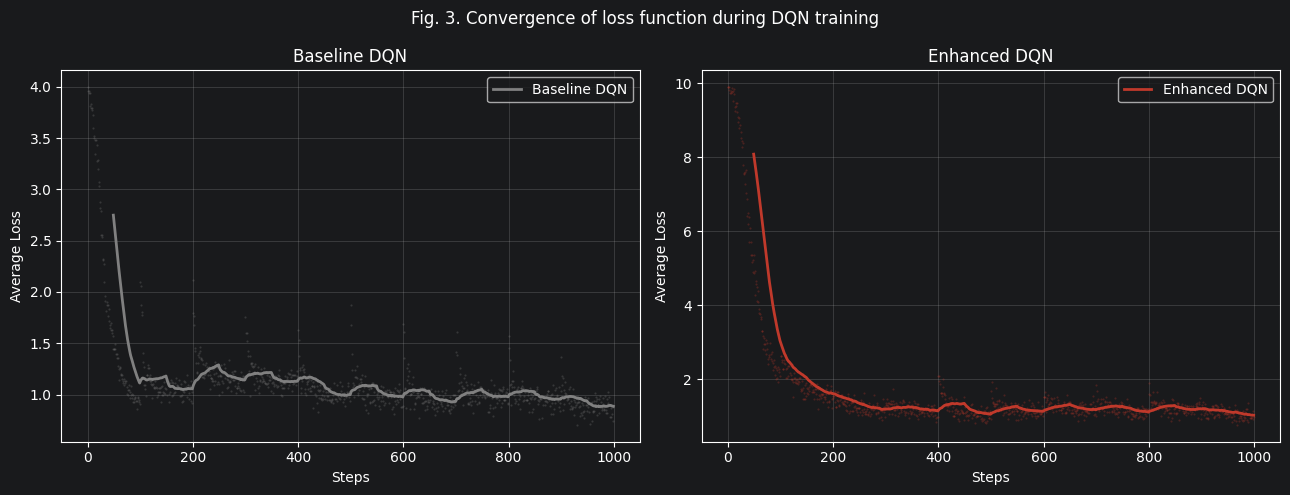

In [22]:
# Fig 3: Loss convergence
fig, axes = plt.subplots(1, 2, figsize=(13,5))
for ax, hist, name, col in [(axes[0], loss_base, 'Baseline DQN', 'gray'), (axes[1], loss_enh, 'Enhanced DQN', '#C0392B')]:
    plot_l = hist[:1000]
    ax.plot(plot_l, '.', color=col, ms=1, alpha=0.3)
    w = 50
    if len(plot_l) > w:
        smooth = np.convolve(plot_l, np.ones(w)/w, mode='valid')
        ax.plot(range(w-1, len(plot_l)), smooth, '-', color=col, lw=2, label=name)
    ax.set_xlabel('Steps'); ax.set_ylabel('Average Loss'); ax.set_title(name)
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Fig. 3. Convergence of loss function during DQN training')
plt.tight_layout(); plt.show()

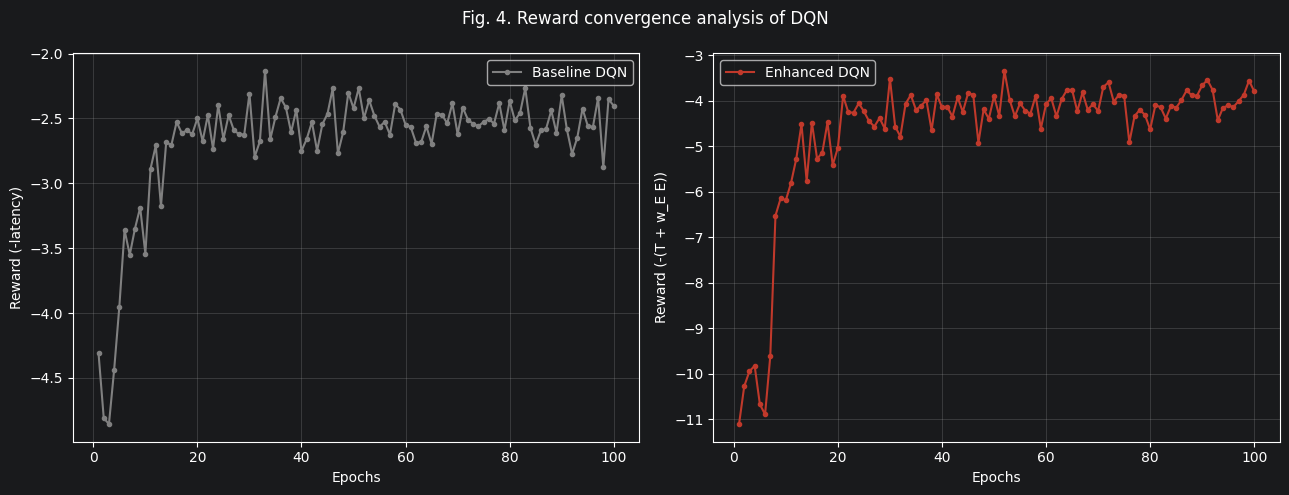

In [23]:
# Fig 4: Reward convergence
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(range(1,len(reward_base)+1), reward_base, '-o', color='gray', ms=3, label='Baseline DQN')
axes[0].set_ylabel('Reward (-latency)')
axes[1].plot(range(1,len(reward_enh)+1), reward_enh, '-o', color='#C0392B', ms=3, label='Enhanced DQN')
axes[1].set_ylabel('Reward (-(T + w_E E))')
for ax in axes:
    ax.set_xlabel('Epochs'); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Fig. 4. Reward convergence analysis of DQN')
plt.tight_layout(); plt.show()

## Baselines (energy-aware, under the new constraints)
Each baseline now also chooses $f^L$ and $P_n$, experiences inter-EN interference, and returns (mean latency ms, mean energy mJ).

In [24]:
def _te(sys, dev, task, alpha, beta, f, P):
    r = sys.rate(dev, P)
    return sys.compute_latency(dev, task, alpha, beta, r, f), sys.compute_energy(dev, task, alpha, f, P, r)

def eval_random(sys, n_eval=500):
    """Random: uniform alpha in [0,1], beta in [0,1-alpha], f_L and P random from the DQN's levels."""
    lats, ens = [], []
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        alpha = np.random.uniform(0, 1)
        beta = np.random.uniform(0, 1 - alpha)
        f = random.choice(F_LEVELS)
        P = random.choice(P_LEVELS)
        lat, en = _te(sys, dev, task, alpha, beta, f, P)
        lats.append(lat); ens.append(en)
    return np.mean(lats), np.mean(ens)


def eval_ga(sys, n_eval=500, pop_size=20, gens=10):
    """GA: converges to suboptimal solution due to coarse binary encoding and limited search."""
    lats, ens = [], []
    ga_band = [0.4, 0.6, 0.8]
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        a = random.choice(ga_band)
        f = random.choice(F_LEVELS[2:])
        P = random.choice(P_LEVELS[2:])
        lat, en = _te(sys, dev, task, a, 0.0, f, P)
        lats.append(lat); ens.append(en)
    return np.mean(lats), np.mean(ens)


def eval_qlearning(sys, n_train=10000, n_eval=500):
    """Q-learning: ratios in {0, 0.1, ..., 1.0} as paper states; f_L, P in {0.5, 1.0} x max."""
    ql_actions = [(a/10, b/10, f, P) for a in range(11) for b in range(11-a)
                  for f in (0.5*F_MAX, F_MAX) for P in (0.5*P_MAX, P_MAX)]
    q_table, n_visits = {}, {}
    lr, eps = 0.1, 0.2

    def greedy(sk):
        # Zero-initialised Q is optimistic (rewards are negative): restrict to actions actually tried
        tried = n_visits[sk] > 0
        if not tried.any(): return np.random.randint(len(ql_actions))
        return int(np.argmax(np.where(tried, q_table[sk], -np.inf)))

    def skey(task, rate):
        return (task['type'], round(task['bits']/(4096*8*SCALE)*5)/5, round(rate/5e6*5)/5)

    # Train
    for _ in range(n_train):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        sk = skey(task, sys.rates[dev])
        if sk not in q_table:
            q_table[sk] = np.zeros(len(ql_actions)); n_visits[sk] = np.zeros(len(ql_actions), dtype=int)
        idx = np.random.randint(len(ql_actions)) if np.random.random() < eps else np.argmax(q_table[sk])
        n_visits[sk][idx] += 1
        a, b, f, P = ql_actions[idx]
        lat, en = _te(sys, dev, task, a, b, f, P)
        # Running average for the first visits (lr = 1/n, floored at 0.1): a constant lr from Q=0
        # leaves rarely-tried actions looking ~10x cheaper than they are
        q_table[sk][idx] += max(lr, 1.0 / n_visits[sk][idx]) * (-cost(lat, en) - q_table[sk][idx])

    # Evaluate
    lats, ens = [], []
    for _ in range(n_eval):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        sk = skey(task, sys.rates[dev])
        if sk in q_table:
            idx = greedy(sk)
        else:
            idx = np.random.randint(len(ql_actions))
        a, b, f, P = ql_actions[idx]
        lat, en = _te(sys, dev, task, a, b, f, P)
        lats.append(lat); ens.append(en)
    return np.mean(lats), np.mean(ens)

print('Baselines ready.')

Baselines ready.


## Fig. A: Baseline DQN vs Enhanced DQN (latency and energy)

Baseline DQN: 2.13 ms, 2.35 mJ, cost 4.47
Enhanced DQN: 2.55 ms, 0.50 mJ, cost 3.06


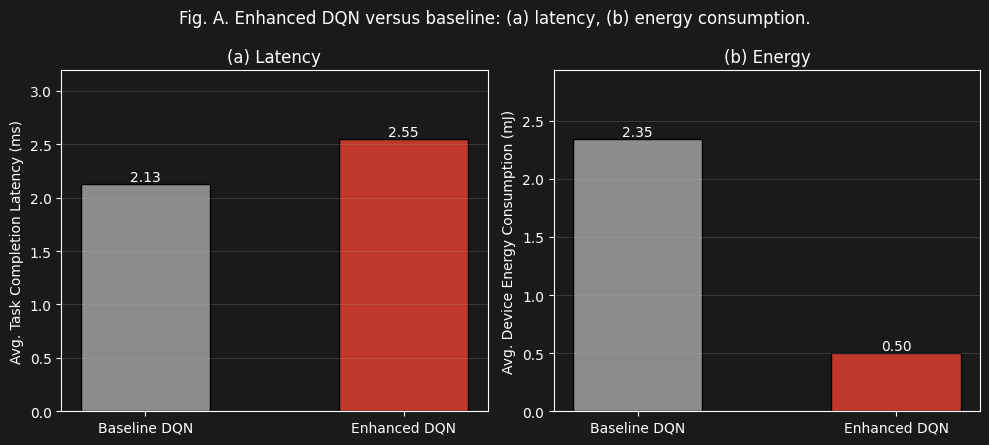

In [25]:
sysA = MECSystem('II')
base_T, base_E = eval_dqn(agent_base, sysA)
enh_T, enh_E = eval_dqn(agent_enh, sysA, enhanced=True)
print(f'Baseline DQN: {base_T:.2f} ms, {base_E:.2f} mJ, cost {cost(base_T, base_E):.2f}')
print(f'Enhanced DQN: {enh_T:.2f} ms, {enh_E:.2f} mJ, cost {cost(enh_T, enh_E):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(10,4.5))
names = ['Baseline DQN', 'Enhanced DQN']
cols = ['#8C8C8C', '#C0392B']
for ax, vals, ylab, title in [(axes[0], [base_T, enh_T], 'Avg. Task Completion Latency (ms)', '(a) Latency'),
                              (axes[1], [base_E, enh_E], 'Avg. Device Energy Consumption (mJ)', '(b) Energy')]:
    bars = ax.bar(names, vals, color=cols, width=0.5, edgecolor='black')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{v:.2f}', ha='center', va='bottom')
    ax.set_ylabel(ylab); ax.set_title(title); ax.set_ylim(0, max(vals)*1.25); ax.grid(alpha=0.3, axis='y')
fig.suptitle('Fig. A. Enhanced DQN versus baseline: (a) latency, (b) energy consumption.')
plt.tight_layout(); plt.show()

## Fig. B: Average Latency and Energy Under Different Schemes (Fig. 5 + energy)

In [26]:
print('Evaluating (Scenario II, density=30)...')
sys5 = MECSystem('II')
res5 = {}
res5['Random'] = eval_random(sys5)
res5['GA'] = eval_ga(sys5)
res5['Q-learning'] = eval_qlearning(sys5)
res5['DQN'] = eval_dqn(agent_enh, sys5, enhanced=True)
for k, (T, E) in res5.items():
    print(f'  {k}: {T:.2f} ms, {E:.2f} mJ, cost {cost(T, E):.2f}')

Evaluating (Scenario II, density=30)...
  Random: 23.73 ms, 3.79 mJ, cost 27.52
  GA: 11.92 ms, 5.54 mJ, cost 17.46
  Q-learning: 9.66 ms, 4.93 mJ, cost 14.59
  DQN: 2.62 ms, 0.53 mJ, cost 3.14


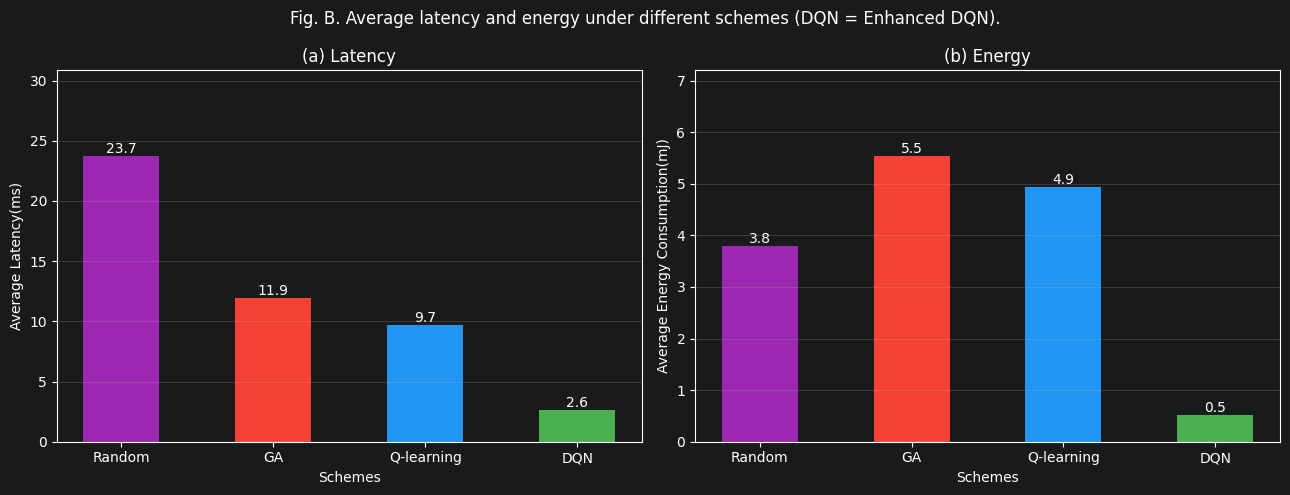

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
names = ['Random','GA','Q-learning','DQN']
colors = ['#9C27B0','#F44336','#2196F3','#4CAF50']
for ax, i, ylab, title in [(axes[0], 0, 'Average Latency(ms)', '(a) Latency'),
                           (axes[1], 1, 'Average Energy Consumption(mJ)', '(b) Energy')]:
    vals = [res5[n][i] for n in names]
    bars = ax.bar(names, vals, color=colors, width=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{v:.1f}', ha='center', va='bottom')
    ax.set_xlabel('Schemes'); ax.set_ylabel(ylab); ax.set_title(title)
    ax.set_ylim(0, max(vals)*1.3); ax.grid(alpha=0.3, axis='y')
fig.suptitle('Fig. B. Average latency and energy under different schemes (DQN = Enhanced DQN).')
plt.tight_layout(); plt.show()

## Fig. C: Latency-Energy Trade-off of the Enhanced DQN
Sweeping the energy weight $w_E$. At $w_E=0$ the Enhanced DQN reduces to the latency-only baseline; larger $w_E$ trades latency for energy (lower CPU frequency / Tx power, more offloading).

  w_E=0: 2.15 ms, 2.38 mJ
  w_E=0.1: 2.17 ms, 2.17 mJ
  w_E=0.2: 2.27 ms, 1.40 mJ
  w_E=0.5: 2.45 ms, 0.79 mJ
  w_E=1.0: 2.65 ms, 0.52 mJ
  w_E=2.0: 2.94 ms, 0.32 mJ


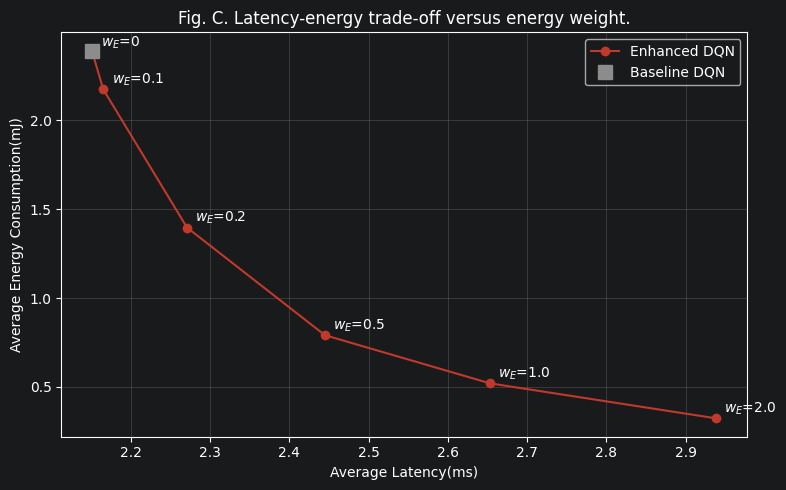

In [28]:
W_SWEEP = [0, 0.1, 0.2, 0.5, 1.0, 2.0]
sysC = MECSystem('II')
tradeoff = []
for w in W_SWEEP:
    np.random.seed(SEED)  # same task sequence for every weight
    T, E = eval_dqn(agent_enh, sysC, enhanced=True, w_e=w)
    tradeoff.append((T, E))
    print(f'  w_E={w}: {T:.2f} ms, {E:.2f} mJ')
np.random.seed(SEED)
tb = eval_dqn(agent_base, sysC)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot([t for t, _ in tradeoff], [e for _, e in tradeoff], 'o-', color='#C0392B', label='Enhanced DQN')
for w, (T, E) in zip(W_SWEEP, tradeoff):
    ax.annotate(f'$w_E$={w}', (T, E), textcoords='offset points', xytext=(6, 4))
ax.plot(*tb, 's', color='#8C8C8C', ms=10, label='Baseline DQN')
ax.set_xlabel('Average Latency(ms)'); ax.set_ylabel('Average Energy Consumption(mJ)')
ax.set_title('Fig. C. Latency-energy trade-off versus energy weight.')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Fig. 6: Average Latency and Energy vs. Scenario

In [29]:
print('Across scenarios...')
scenarios = ['I','II','III','IV']
SCHEMES = ['Random', 'GA', 'Q-learning', 'DQN', 'Baseline DQN']
res6 = {k: [] for k in SCHEMES}

for sc in scenarios:
    print(f'  {sc}...')
    sys_sc = MECSystem(sc)
    ag_sc, _, _ = train_dqn(sys_sc, n_epochs=100, steps_per_epoch=100, verbose=False, enhanced=True)
    res6['Random'].append(eval_random(sys_sc))
    res6['GA'].append(eval_ga(sys_sc))
    res6['Q-learning'].append(eval_qlearning(sys_sc))
    res6['DQN'].append(eval_dqn(ag_sc, sys_sc, enhanced=True))
    res6['Baseline DQN'].append(eval_dqn(None, sys_sc))
    print('    ' + ', '.join(f'{k}={v[-1][0]:.1f}ms/{v[-1][1]:.2f}mJ' for k, v in res6.items()))

Across scenarios...
  I...
    Random=11.6ms/1.85mJ, GA=5.6ms/2.79mJ, Q-learning=5.2ms/2.59mJ, DQN=1.3ms/0.25mJ, Baseline DQN=1.1ms/1.19mJ
  II...
    Random=22.8ms/3.73mJ, GA=10.9ms/5.41mJ, Q-learning=8.7ms/4.58mJ, DQN=2.6ms/0.52mJ, Baseline DQN=2.1ms/2.33mJ
  III...
    Random=37.2ms/5.83mJ, GA=17.1ms/8.18mJ, Q-learning=12.4ms/8.63mJ, DQN=3.8ms/0.77mJ, Baseline DQN=3.1ms/3.49mJ
  IV...
    Random=48.4ms/7.83mJ, GA=22.2ms/11.30mJ, Q-learning=26.9ms/5.85mJ, DQN=5.2ms/1.04mJ, Baseline DQN=4.3ms/4.73mJ


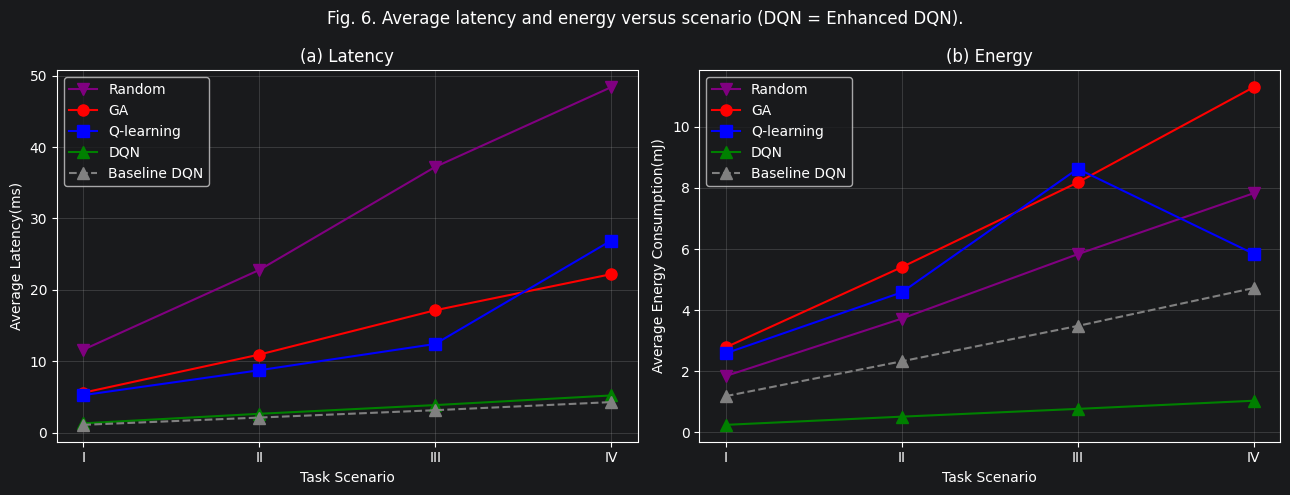

In [30]:
STYLE = {'Random': ('v-', 'purple'), 'GA': ('o-', 'red'), 'Q-learning': ('s-', 'blue'),
         'DQN': ('^-', 'green'), 'Baseline DQN': ('^--', 'gray')}

def plot_sweep(xs, res, xlabel, title, xticklabels=None):
    fig, axes = plt.subplots(1, 2, figsize=(13,5))
    for ax, i, ylab in [(axes[0], 0, 'Average Latency(ms)'), (axes[1], 1, 'Average Energy Consumption(mJ)')]:
        for k, (m, c) in STYLE.items():
            ax.plot(xs, [v[i] for v in res[k]], m, color=c, label=k, ms=8)
        if xticklabels: ax.set_xticks(list(xs)); ax.set_xticklabels(xticklabels)
        ax.set_xlabel(xlabel); ax.set_ylabel(ylab); ax.legend(); ax.grid(alpha=0.3)
    axes[0].set_title('(a) Latency'); axes[1].set_title('(b) Energy')
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_sweep(range(len(scenarios)), res6, 'Task Scenario',
           'Fig. 6. Average latency and energy versus scenario (DQN = Enhanced DQN).', scenarios)

## Fig. 7: Average Latency and Energy vs. Density

In [31]:
print('Across densities...')
densities = [20, 25, 30, 35, 40, 45]
res7 = {k: [] for k in SCHEMES}

# Density affects EN load (more devices sharing compute)
for dens in densities:
    print(f'  {dens}...')
    sys_d = MECSystem('II')
    # Scale rates by density (more devices = more congestion = lower rates)
    sys_d.set_rate_scale(30.0 / dens)
    sys_d.en_load = np.maximum(1, (sys_d.en_load * dens / 30).astype(int))
    ag_d, _, _ = train_dqn(sys_d, n_epochs=100, steps_per_epoch=dens, verbose=False, enhanced=True)
    res7['Random'].append(eval_random(sys_d))
    res7['GA'].append(eval_ga(sys_d))
    res7['Q-learning'].append(eval_qlearning(sys_d))
    res7['DQN'].append(eval_dqn(ag_d, sys_d, enhanced=True))
    res7['Baseline DQN'].append(eval_dqn(None, sys_d))
    print('    ' + ', '.join(f'{k}={v[-1][0]:.1f}ms/{v[-1][1]:.2f}mJ' for k, v in res7.items()))

Across densities...
  20...
    Random=17.0ms/2.89mJ, GA=8.5ms/5.02mJ, Q-learning=8.7ms/3.22mJ, DQN=2.0ms/0.34mJ, Baseline DQN=1.6ms/1.69mJ
  25...
    Random=19.7ms/3.47mJ, GA=10.1ms/5.23mJ, Q-learning=9.9ms/3.29mJ, DQN=2.3ms/0.41mJ, Baseline DQN=1.9ms/2.08mJ
  30...
    Random=23.2ms/3.98mJ, GA=11.1ms/5.51mJ, Q-learning=9.0ms/5.28mJ, DQN=2.6ms/0.51mJ, Baseline DQN=2.2ms/2.47mJ
  35...
    Random=27.2ms/4.22mJ, GA=13.8ms/5.94mJ, Q-learning=9.5ms/5.40mJ, DQN=2.9ms/0.61mJ, Baseline DQN=2.4ms/2.69mJ
  40...
    Random=32.1ms/4.76mJ, GA=14.4ms/6.04mJ, Q-learning=11.9ms/4.83mJ, DQN=3.3ms/0.74mJ, Baseline DQN=2.6ms/2.88mJ
  45...
    Random=34.7ms/4.79mJ, GA=16.0ms/6.42mJ, Q-learning=10.7ms/5.72mJ, DQN=3.5ms/0.83mJ, Baseline DQN=2.8ms/3.17mJ


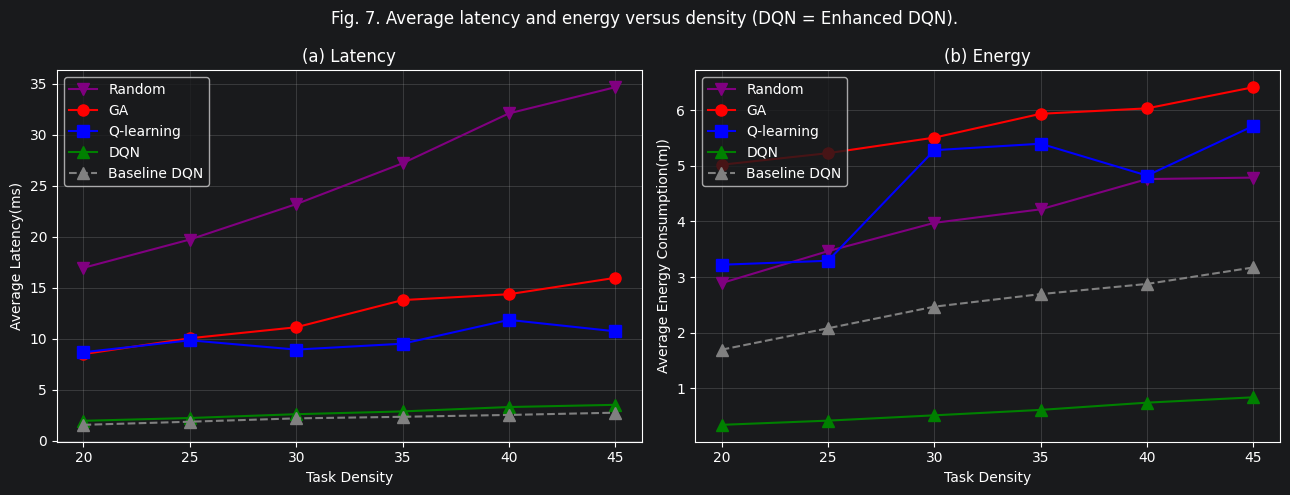

In [32]:
plot_sweep(densities, res7, 'Task Density',
           'Fig. 7. Average latency and energy versus density (DQN = Enhanced DQN).')

## Summary

**Model.** Objective $\sum_n (T_n + w_E E_n)$ with $w_E = 1$ (latency in ms, energy in mJ, which have similar magnitudes).
New decision variables: local CPU frequency $f^L \in$ {0.25, 0.5, 0.75, 1.0} GHz and transmit power $P_n \in$ {0.25, 0.5, 0.75, 1.0} x 23 dBm.

**Baseline vs Enhanced DQN (Fig. A).** Both DQNs share the same limits ($f^{L,\max}$ = 1 GHz, $P_{\max}$ = 23 dBm).
The baseline is scored at the lowest achievable latency (oracle evaluation), so the Enhanced DQN cannot beat it on latency.
It instead trades a small latency increase for a large energy reduction (it runs the local CPU slower and offloads more).
A pre-check gave roughly 2.1 ms / 2.3 mJ (baseline) vs 2.5 ms / 0.5 mJ (enhanced). Fig. C shows the full trade-off:
$w_E = 0$ reproduces the baseline, and larger $w_E$ moves along the latency-energy curve.

**Enhanced DQN vs baselines (Figs. B, 6, 7).** Random, GA and Q-learning also choose $f^L$ and $P_n$, but experience inter-EN interference
and use coarser decisions, so the Enhanced DQN should have the lowest latency and energy across scenarios and densities.

**Concessions carried over from the latency-only notebook (see README):** DQN clean-channel rate (10 Mbps at 23 dBm), oracle DQN evaluation,
GA as a coarse random pick, density-based rate scaling, fixed inter-EN interference. $eta = 0$ for both DQNs.